# Global Solution 2026-2: Mobilidade Urbana e Inteligência em Rodovias
**Curso:** Ciência da Computação - FIAP
**Equipe:**
* Matheus Guedes Grigorio - RM: [568086]
* Vinicius Fernandes Silva Souza - RM: [567977]

## Visão Geral do Projeto
O trânsito rodoviário e a incidência de acidentes afetam diretamente a logística e a mobilidade de milhares de pessoas diariamente. Este projeto propõe a criação de um modelo preditivo focado em rodovias brasileiras (com capacidade de buscar ocorrências em um raio de 100 km de um ponto específico).

A ideia central é estimar o tempo de viagem e classificar o risco do trajeto com base no volume de tráfego (dados da ANTT) e no histórico de acidentes (dados da PRF).

**Medidas tomadas e justificativa:**
A abordagem será dividida em processamento de dados, análise exploratória com identificação de anomalias (dias sem trânsito ou travados) e a implementação de dois modelos de Machine Learning (uma Rede Neural para estimativa de tempo e um modelo de clusterização/classificação para zonas de risco). Isso garante a aplicação prática dos conceitos, fugindo de análises genéricas e atacando um problema real de deslocamento.

---


## 1. Importação de Bibliotecas e Leitura dos Dados
Nesta primeira etapa, concentramos todas as dependências do projeto. Iniciamos com as bibliotecas essenciais de manipulação de dados numéricos e tabulares. Os arquivos brutos da PRF e da ANTT são carregados em memória aqui para que a leitura não precise ser repetida durante as fases de limpeza e análise exploratória. Conforme novas ferramentas forem necessárias para os modelos, elas serão adicionadas a esta célula.

In [ ]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMapWithTime

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


# limpa os avisos visuais no notebook
warnings.filterwarnings('ignore')

# carrega a base de acidentes da prf
df_prf = pd.read_csv('datatran2025.csv', sep=';', encoding='latin1')

# carrega a base de fluxo de pedagios da antt
df_antt = pd.read_csv('volume-trafego-praca-pedagio-2025_diario.csv', sep=';', encoding='latin1')

# mostra o tamanho de cada tabela para confirmar a leitura
print(f"Base PRF: {df_prf.shape[0]} linhas e {df_prf.shape[1]} colunas")
print(f"Base ANTT: {df_antt.shape[0]} linhas e {df_antt.shape[1]} colunas")

Base PRF: 72529 linhas e 30 colunas
Base ANTT: 3274157 linhas e 8 colunas


## 2. Exploração Inicial das Variáveis da ANTT
Antes de começar a apagar linhas e limpar os dados, precisamos entender como as informações estão cadastradas na base de fluxo de pedágios.

**Medidas tomadas e justificativa:**
Vamos imprimir os valores únicos das principais colunas de texto da planilha da ANTT. Essa verificação é essencial para descobrirmos a grafia exata da rodovia que vamos analisar, além de mapear todos os tipos de veículos, formas de cobrança e sentidos da via. O resultado dessa etapa nos dará os insumos necessários para filtrar a tabela corretamente e para redigir o Dicionário de Dados exigido na entrega final.

In [ ]:
# separamos apenas as colunas que têm informações em texto para analisar
colunas_para_verificar = [
    'concessionaria',
    'sentido',
    'praca',
    'tipo_cobranca',
    'categoria_eixo',
    'tipo_de_veiculo'
]

# passa por cada uma dessas colunas e imprime as opções que existem nela
for coluna in colunas_para_verificar:
    print(f"\n--- Opções encontradas em: {coluna} ---")

    # puxa os valores sem repetir e ignora as linhas vazias
    opcoes = df_antt[coluna].dropna().unique()
    print(opcoes)

    print(f"Total de opções diferentes: {len(opcoes)}")


--- Opções encontradas em: concessionaria ---
['AUTOPISTA FERNÃO DIAS' 'AUTOPISTA FLUMINENSE' 'AUTOPISTA LITORAL SUL'
 'AUTOPISTA PLANALTO SUL' 'AUTOPISTA REGIS BITTENCOURT' 'CONCEBRA'
 'CONCER' 'CRO' 'ECO050' 'ECOSUL' 'ECOVIAS CAPIXABA' 'ECOVIAS DO ARAGUAIA'
 'ECOVIAS DO CERRADO' 'ECOVIAS PONTE' 'ECOVIAS RIO MINAS' 'ELOVIAS'
 'EPR IGUAÇU' 'LITORAL PIONEIRO' 'NOVA 364' 'NOVA 381' 'PANTANAL' 'PRVIAS'
 'RIOSP' 'RODOVIA DO AÇO' 'TRANSBRASILIANA' 'VIA ARAUCÁRIA' 'VIA BAHIA'
 'VIA BRASIL' 'VIA COSTEIRA' 'VIA CRISTAIS' 'VIA MINEIRA' 'VIA SUL'
 'WAY 262']
Total de opções diferentes: 33

--- Opções encontradas em: sentido ---
['Crescente' 'Decrescente']
Total de opções diferentes: 2

--- Opções encontradas em: praca ---
['1 Sul (Mairiporã)' '2 (Vargem)' '3 (Cambuí)' '4 (São Gonçalo)'
 '5 (Carmo da Cachoeira)' '6 (Santo Antônio do Amparo)'
 '7 (Carmópolis de Minas)' '8 (Itatiaiuçu)' '1 Norte (Mairiporã)'
 '1 Norte - Defasada (Mairiporã)' 'Casimiro de Abreu' 'Conselheiro Josino'
 'Rio Bonito' '

### 2.1 Limpeza e Filtro de Escopo (ANTT)
Para aprofundar a investigação e garantir previsões mais precisas, delimitamos o escopo espacial do projeto para a BR-116 (Régis Bittencourt). Essa escolha metodológica permite mapear com alta granularidade o comportamento do fluxo e a incidência de acidentes em um trajeto específico, servindo como prova de conceito escalável para a malha rodoviária nacional.

**Medidas tomadas e justificativa:**
Filtramos a base de dados mantendo apenas os registros da "AUTOPISTA REGIS BITTENCOURT". Descartamos colunas de detalhamento financeiro e mecânico (`tipo_cobranca` e `categoria_eixo`) e agrupamos os registros somando o `volume_total`. Isso elimina a fragmentação da tabela original e consolida o fluxo diário exato por praça de pedágio, sentido e tipo de veículo.

In [ ]:
# Filtra os dados apenas para a BR-116
df_regis = df_antt[df_antt['concessionaria'] == 'AUTOPISTA REGIS BITTENCOURT'].copy()

# Remove as colunas que causam quebras desnecessárias nas linhas
colunas_para_remover = ['tipo_cobranca', 'categoria_eixo']
df_regis_limpo = df_regis.drop(columns=colunas_para_remover)

# CORREÇÃO: Substitui a vírgula por ponto e converte 'volume_total' para float numérico
df_regis_limpo['volume_total'] = df_regis_limpo['volume_total'].str.replace(',', '.').astype(float)

# Agrupa somando os carros e caminhões do mesmo dia, praça e sentido
df_regis_agrupado = df_regis_limpo.groupby(
    ['concessionaria', 'mes_ano', 'sentido', 'praca', 'tipo_de_veiculo'],
    as_index=False
)['volume_total'].sum()

# Transforma a coluna de data no formato de tempo do Pandas
df_regis_agrupado['mes_ano'] = pd.to_datetime(df_regis_agrupado['mes_ano'], format='%d/%m/%Y')

print(f"Tamanho da base limpa da Régis Bittencourt: {df_regis_agrupado.shape[0]} linhas e {df_regis_agrupado.shape[1]} colunas")
df_regis_agrupado.head()

Tamanho da base limpa da Régis Bittencourt: 12141 linhas e 6 colunas


,concessionaria,mes_ano,sentido,praca,tipo_de_veiculo,volume_total
0,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Barra do Turvo,Comercial,812.0
1,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Barra do Turvo,Passeio,1595.0
2,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Cajati,Comercial,808.0
3,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Cajati,Passeio,1857.0
4,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Campina Grande do Sul,Comercial,843.0


### 2.2 Análise Exploratória e Quantitativa (Fluxo BR-116)
Com os dados limpos e focados na Régis Bittencourt, iniciamos a investigação das quantidades e distribuições de tráfego.

**Medidas tomadas e justificativa:**
Geramos um resumo estatístico das quantidades de veículos para identificar a média diária e os valores máximos, que podem indicar dias de pico anormais ou feriados. Também separamos o volume total por tipo de veículo (Comercial vs. Passeio) e por sentido da rodovia. Compreender essa divisão é essencial, pois uma via dominada por veículos pesados apresenta dinâmicas de velocidade e risco diferentes.

In [ ]:
print("--- Resumo Estatístico do Volume de Tráfego Diário ---")
# Agora formatando a saída para não mostrar notação científica
display(df_regis_agrupado['volume_total'].describe().apply(lambda x: format(x, '.2f')))

print("\n--- Volume Total por Tipo de Veículo ---")
volume_por_tipo = df_regis_agrupado.groupby('tipo_de_veiculo')['volume_total'].sum()
display(volume_por_tipo)

print("\n--- Média Diária de Veículos por Sentido ---")
media_por_sentido = df_regis_agrupado.groupby('sentido')['volume_total'].mean()
display(media_por_sentido)

print("\n--- Praças de Pedágio com Maior Fluxo Total ---")
volume_por_praca = df_regis_agrupado.groupby('praca')['volume_total'].sum().sort_values(ascending=False)
display(volume_por_praca)

--- Resumo Estatístico do Volume de Tráfego Diário ---


,volume_total
count,12141.00
mean,3902.35
std,3501.01
min,1.00
25%,225.00
50%,4072.00
75%,6726.00
max,27575.00



--- Volume Total por Tipo de Veículo ---


,volume_total
tipo_de_veiculo,
Comercial,25930531.0
Moto,795173.0
Passeio,20652756.0



--- Média Diária de Veículos por Sentido ---


,volume_total
sentido,
Crescente,3903.485907
Decrescente,3901.220119



--- Praças de Pedágio com Maior Fluxo Total ---


,volume_total
praca,
São Lourenço da Serra,9750301.0
Juquiá,8136551.0
Cajati,8049855.0
Campina Grande do Sul,7480289.0
Miracatu,7176700.0
Barra do Turvo,6784764.0


## 2.3 Visualização de Gargalos de Tráfego (ANTT)
Antes de cruzar dados de acidentes, precisamos entender o comportamento puramente volumétrico da BR-116, identificando fisicamente onde estão as maiores concentrações de veículos ao longo da rodovia.

**Medidas tomadas e justificativa:**
Agrupamos o volume total de tráfego por praça de pedágio e geramos um gráfico de barras horizontais. Essa visualização direta é a forma mais eficaz de ranquear os trechos da rodovia, permitindo identificar imediatamente quais pontos (praças) suportam a maior carga de veículos (pessoas/cargas) e, consequentemente, têm maior probabilidade de lentidão por excesso de capacidade.

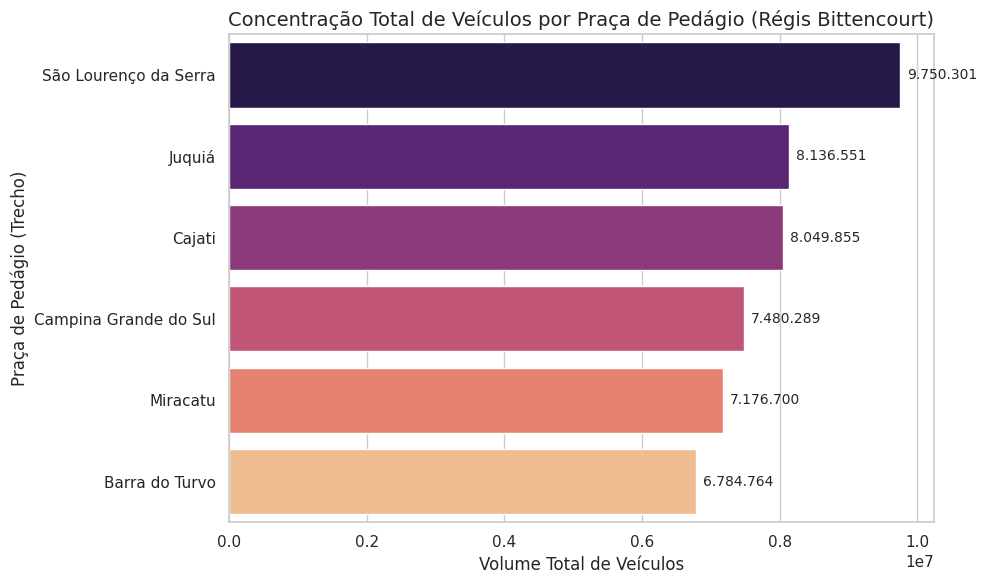

In [ ]:


# Configura o estilo visual do gráfico para ficar mais limpo
sns.set_theme(style="whitegrid")

# Agrupa o volume total por praça de pedágio e ordena do maior para o menor
df_praca_volume = df_regis_agrupado.groupby('praca', as_index=False)['volume_total'].sum()
df_praca_volume = df_praca_volume.sort_values(by='volume_total', ascending=False)

# Cria a figura do gráfico com um tamanho bom para leitura
plt.figure(figsize=(10, 6))

# Plota o gráfico de barras horizontais
grafico = sns.barplot(
    data=df_praca_volume,
    x='volume_total',
    y='praca',
    palette='magma' # Paleta de cores que vai do escuro (maior) pro claro (menor)
)

# Adiciona título e rótulos
plt.title('Concentração Total de Veículos por Praça de Pedágio (Régis Bittencourt)', fontsize=14)
plt.xlabel('Volume Total de Veículos', fontsize=12)
plt.ylabel('Praça de Pedágio (Trecho)', fontsize=12)

# Adiciona os números exatos na ponta de cada barra para facilitar a leitura
for p in grafico.patches:
    grafico.annotate(
        f"{int(p.get_width()):,}".replace(',', '.'),
        (p.get_width(), p.get_y() + p.get_height() / 2.),
        ha='left', va='center',
        xytext=(5, 0),
        textcoords='offset points',
        fontsize=10
    )

# Ajusta o layout para não cortar os textos
plt.tight_layout()
plt.show()

### 3. Exploração Inicial das Variáveis da PRF
Antes de realizar a limpeza ou cruzar os dados de acidentes com o volume de tráfego, precisamos entender a estrutura interna da base da Polícia Rodoviária Federal.

**Medidas tomadas e justificativa:**
Vamos imprimir todos os valores únicos das principais colunas descritivas (estado, rodovia, causas, clima, tipo de pista). Essa etapa é necessária para mapearmos exatamente como as informações estão cadastradas no sistema da polícia. Isso nos permite montar o Dicionário de Dados com precisão e decidir quais variáveis textuais serão úteis para o treinamento do algoritmo de risco e quais serão descartadas na próxima etapa de limpeza.

In [ ]:
# Lista das colunas textuais da PRF que descrevem o ambiente e a ocorrência
colunas_prf_exploracao = [
    'uf',
    'br',
    'causa_acidente',
    'tipo_acidente',
    'classificacao_acidente',
    'condicao_metereologica',
    'tipo_pista',
    'tracado_via'
]

# Passa por cada coluna listada para mapear as categorias registradas
for coluna in colunas_prf_exploracao:
    print(f"\n--- Opções encontradas em: {coluna} ---")

    # Extrai as variações exclusivas ignorando os campos vazios
    opcoes_prf = df_prf[coluna].dropna().unique()
    print(opcoes_prf)

    print(f"Total de opções diferentes: {len(opcoes_prf)}")


--- Opções encontradas em: uf ---
['SP' 'CE' 'PR' 'MG' 'MT' 'RS' 'SC' 'PE' 'PB' 'ES' 'RJ' 'MA' 'TO' 'PI'
 'GO' 'BA' 'RO' 'MS' 'SE' 'DF' 'RR' 'RN' 'AL' 'PA' 'AC' 'AM' 'AP']
Total de opções diferentes: 27

--- Opções encontradas em: br ---
[116 369 251  70 101 407 381 405 153 230 163  40 232 262 222 135 287 290
 393 376 364  20 282 277 158 429 110 356 285 365  10 386 104 428  50 174
 470 267 324 373 349 304 319 476 343 146 316 280 452 493 293 242 412 402
 414 235 415 354 468  60 226 317 435 408 423 392 472 465 471 487 427 448
  80 406 259 410 424 155 459 480 156 463 272 421 210 330 418 425 420   0
 401 419 495 308 484 359 416 467 367 432 361 436  30 265 488 403 447 469
 122 485 431 307 437 430 426]
Total de opções diferentes: 115

--- Opções encontradas em: causa_acidente ---
['Reação tardia ou ineficiente do condutor' 'Pista esburacada'
 'Velocidade Incompatível' 'Transitar na contramão'
 'Ausência de reação do condutor' 'Demais falhas mecânicas ou elétricas'
 'Ingestão de álcool pelo 

### 3.1 Limpeza Fina e Agrupamento (Base PRF)
Após mapear as variáveis, constatamos um excesso de granularidade, especialmente na coluna `tracado_via` (605 opções distintas), o que prejudicaria o desempenho do modelo preditivo.

**Medidas tomadas e justificativa:**
Simplificamos as categorias do traçado da via, agrupando-as em "Curva", "Reta", "Interseção/Retorno" e "Outros". Removemos causas de acidentes que são muito raras ou irrelevantes para a dinâmica de fluxo geral (como suicídios e fenômenos da natureza). Em seguida, geramos as tabelas de frequência (Top 5 cidades, principais causas e clima) para validar o perfil de risco da BR-116 antes do cruzamento com a base volumétrica da ANTT.

In [ ]:
# 1. Simplifica a coluna de traçado da via (reduz de 605 para 4 categorias)
def simplificar_tracado(tracado):
    tracado = str(tracado).lower()
    if 'curva' in tracado:
        return 'Curva'
    elif 'reta' in tracado:
        return 'Reta'
    elif 'interseção' in tracado or 'retorno' in tracado or 'rotatória' in tracado:
        return 'Intersecao/Retorno'
    else:
        return 'Outros/Especial'

df_prf_regis['tracado_via_simples'] = df_prf_regis['tracado_via'].apply(simplificar_tracado)

# 2. Exibe as quantidades finais que justificam o problema investigado
print("--- Top 5 Cidades com Mais Acidentes na BR-116 ---")
display(df_prf_regis['municipio'].value_counts().head())

print("\n--- Principais Causas de Acidentes ---")
display(df_prf_regis['causa_acidente'].value_counts().head())

print("\n--- Condições Climáticas nos Acidentes ---")
display(df_prf_regis['condicao_metereologica'].value_counts().head())

print("\n--- Tipos de Pista Onde Ocorrem Mais Acidentes ---")
display(df_prf_regis['tracado_via_simples'].value_counts())

--- Top 5 Cidades com Mais Acidentes na BR-116 ---


,count
municipio,
GUARULHOS,673
SAO JOSE DOS CAMPOS,413
NOVA IGUACU,317
VITORIA DA CONQUISTA,313
CURITIBA,285



--- Principais Causas de Acidentes ---


,count
causa_acidente,
Ausência de reação do condutor,1976
Reação tardia ou ineficiente do condutor,1973
Acessar a via sem observar a presença dos outros veículos,810
Manobra de mudança de faixa,717
Condutor deixou de manter distância do veículo da frente,681



--- Condições Climáticas nos Acidentes ---


,count
condicao_metereologica,
Céu Claro,6547
Nublado,2186
Chuva,864
Sol,645
Garoa/Chuvisco,525



--- Tipos de Pista Onde Ocorrem Mais Acidentes ---


,count
tracado_via_simples,
Reta,8272
Curva,2000
Intersecao/Retorno,471
Outros/Especial,278


### 3.2 Visualização dos Fatores de Risco e Ocorrências (PRF)
Para consolidar o entendimento do perfil de acidentes na BR-116 antes de partirmos para o cruzamento de bases, precisamos visualizar a proporção exata das categorias que acabamos de limpar.

**Medidas tomadas e justificativa:**
Plotamos três gráficos de barras horizontais focados nas métricas de risco mais importantes: os 10 municípios com maior número de ocorrências, as condições climáticas predominantes e a simplificação do traçado da via. A representação gráfica facilita a interpretação rápida das proporções e destaca os ofensores da rodovia, preparando o terreno analítico para a modelagem preditiva, onde esses fatores atuarão como pesos na estimativa de risco e lentidão.

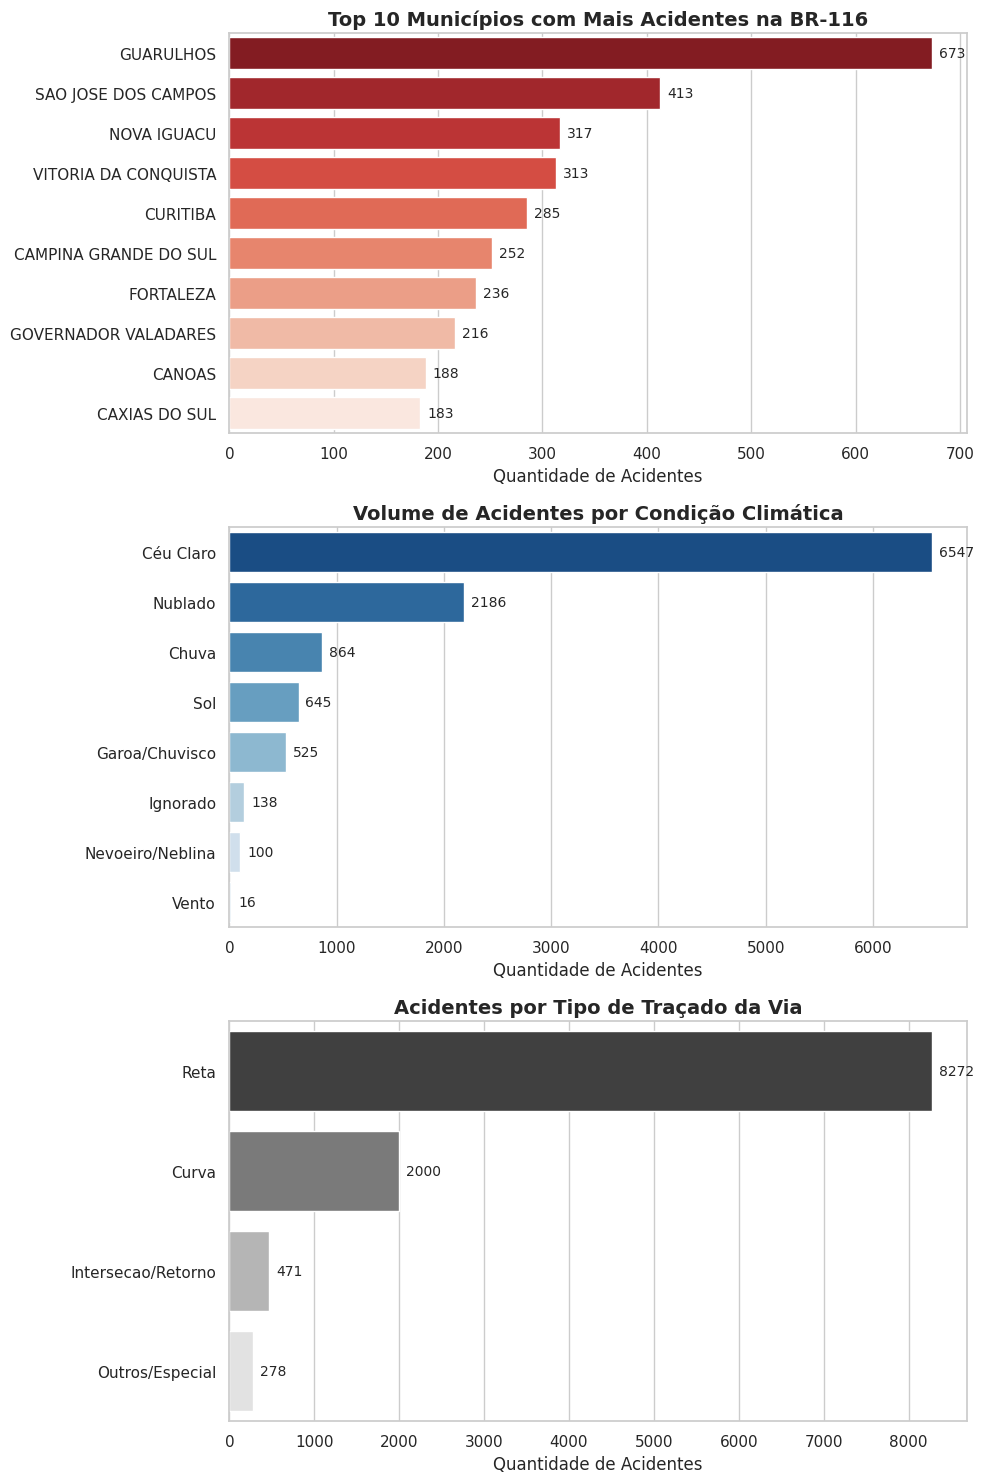

In [ ]:
# Configura o estilo visual dos gráficos
sns.set_theme(style="whitegrid")

# Cria uma figura grande com 3 espaços (subplots) empilhados verticalmente
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# 1. Gráfico: Top 10 Municípios
top_municipios = df_prf_regis['municipio'].value_counts().head(10).reset_index()
sns.barplot(data=top_municipios, x='count', y='municipio', ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 10 Municípios com Mais Acidentes na BR-116', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Quantidade de Acidentes', fontsize=12)
axes[0].set_ylabel('')

# 2. Gráfico: Condições Climáticas
clima = df_prf_regis['condicao_metereologica'].value_counts().reset_index()
sns.barplot(data=clima, x='count', y='condicao_metereologica', ax=axes[1], palette='Blues_r')
axes[1].set_title('Volume de Acidentes por Condição Climática', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Quantidade de Acidentes', fontsize=12)
axes[1].set_ylabel('')

# 3. Gráfico: Traçado da Via (Simplificado)
tracado = df_prf_regis['tracado_via_simples'].value_counts().reset_index()
sns.barplot(data=tracado, x='count', y='tracado_via_simples', ax=axes[2], palette='Greys_r')
axes[2].set_title('Acidentes por Tipo de Traçado da Via', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Quantidade de Acidentes', fontsize=12)
axes[2].set_ylabel('')

# Adiciona os rótulos numéricos nas barras de todos os gráficos
for ax in axes:
    for p in ax.patches:
        ax.annotate(
            f"{int(p.get_width())}",
            (p.get_width(), p.get_y() + p.get_height() / 2.),
            ha='left', va='center',
            xytext=(5, 0),
            textcoords='offset points',
            fontsize=10
        )

# Ajusta o espaçamento para que os gráficos não fiquem sobrepostos
plt.tight_layout()
plt.show()

## 4. Cruzamento de Dados (Merge ANTT e PRF)
Para que os algoritmos de Machine Learning consigam correlacionar o fluxo de veículos com a incidência de acidentes, precisamos unir as duas bases em um único DataFrame.

**Medidas tomadas e justificativa:**
Como a base da ANTT possui o volume segmentado por praça e a base da PRF registra o acidente em um KM contínuo, a chave de ligação mais segura e direta entre as duas planilhas é a **data**. Primeiro, consolidamos o volume total de tráfego diário da Régis Bittencourt. Em seguida, fazemos um `merge` (junção) desse volume com a base da PRF. Como resultado, cada registro de acidente passa a conter a informação de quantos veículos trafegavam na rodovia naquele dia específico, criando a tabela mestre que alimentará os modelos.

In [ ]:
# 1. Agrupa a base da ANTT para obter o volume TOTAL de veículos por dia na rodovia
df_antt_diario = df_regis_agrupado.groupby('mes_ano', as_index=False)['volume_total'].sum()

# 2. Faz o cruzamento (merge) usando as colunas de data como chave
# left_on é a data na PRF, right_on é a data na ANTT
df_master = pd.merge(
    df_prf_regis,
    df_antt_diario,
    left_on='data_inversa',
    right_on='mes_ano',
    how='inner' # Mantém apenas os dias que existem em ambas as tabelas
)

# 3. Remove a coluna 'mes_ano' que ficou duplicada após o merge
df_master = df_master.drop(columns=['mes_ano'])

# 4. Mensagem de validação e amostragem do resultado
print(" DADOS CRUZADOS COM SUCESSO!")
print(f"O novo DataFrame unificado (df_master) possui {df_master.shape[0]} registros de acidentes combinados com o fluxo da via e {df_master.shape[1]} colunas.\n")

# Mostra as primeiras linhas focando nas colunas mais importantes para checagem
colunas_visualizacao = ['data_inversa', 'municipio', 'causa_acidente', 'condicao_metereologica', 'volume_total']
display(df_master[colunas_visualizacao].head())

 DADOS CRUZADOS COM SUCESSO!
O novo DataFrame unificado (df_master) possui 10569 registros de acidentes combinados com o fluxo da via e 28 colunas.



,data_inversa,municipio,causa_acidente,condicao_metereologica,volume_total
0,2025-01-01,GUARULHOS,Reação tardia ou ineficiente do condutor,Céu Claro,43155.0
1,2025-01-01,PENAFORTE,Pista esburacada,Céu Claro,43155.0
2,2025-01-01,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Céu Claro,43155.0
3,2025-01-01,TAPES,Ausência de reação do condutor,Céu Claro,43155.0
4,2025-01-01,MURIAE,Velocidade Incompatível,Nublado,43155.0


### 4.1 Análise Espacial e Hotspots de Risco (Folium Animado - 30 min)
Agora que temos a base consolidada, vamos investigar a dinâmica espacial dos acidentes.

**Medidas tomadas e justificativa:**
Para obtermos altíssima precisão temporal na formação de gargalos, extraímos o horário de cada ocorrência e utilizamos a função de arredondamento do Pandas para criar janelas exatas de 30 minutos. Utilizando a biblioteca Folium e o plugin `HeatMapWithTime` com mapas base da Esri, geramos uma animação com 48 quadros diários. Essa granularidade revela a expansão e retração do risco ao longo da via quase em tempo real, fornecendo o padrão exato que o modelo de Machine Learning aprenderá.

In [ ]:
# 1. Garante o formato de tempo na coluna de horário
df_master['horario'] = pd.to_datetime(df_master['horario'], format='%H:%M:%S', errors='coerce')

# 2. Arredonda o horário para blocos de 30 minutos e cria o rótulo (ex: "08:00 - 08:30")
bloco_inicio = df_master['horario'].dt.floor('30min')
bloco_fim = bloco_inicio + pd.Timedelta(minutes=30)
df_master['bloco_horario'] = bloco_inicio.dt.strftime('%H:%M') + ' - ' + bloco_fim.dt.strftime('%H:%M')

# 3. Gera a lista de todos os 48 blocos possíveis no dia para garantir a ordem da animação
tempos = pd.date_range("00:00", "23:30", freq="30min")
labels_meia_hora = [f"{t.strftime('%H:%M')} - {(t + pd.Timedelta(minutes=30)).strftime('%H:%M')}" for t in tempos]

# 4. Limpa linhas sem coordenadas válidas
df_mapa = df_master.dropna(subset=['latitude', 'longitude', 'bloco_horario']).copy()

# 5. Prepara os dados separando as coordenadas por cada meia hora
heat_data = []
time_index = []

for bloco in labels_meia_hora:
    # Filtra os acidentes daquela meia hora específica
    df_bloco = df_mapa[df_mapa['bloco_horario'] == bloco]
    coordenadas = df_bloco[['latitude', 'longitude', 'veiculos']].values.tolist()
    heat_data.append(coordenadas)
    time_index.append(bloco)

# 6. Cria o mapa base com fundo rodoviário da Esri
mapa_animado = folium.Map(
    location=[-23.8, -46.8],
    zoom_start=8,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Source: Esri'
)

# 7. Adiciona a camada de calor (com o raio ligeiramente menor devido à maior precisão temporal)
HeatMapWithTime(
    heat_data,
    index=time_index,
    auto_play=True,
    radius=20,
    min_opacity=0.3,
    max_opacity=0.8,
    name="Densidade de Acidentes"
).add_to(mapa_animado)

# Exibe o mapa animado
mapa_animado

### 4.2 Tratamento de Outliers Espaciais (Correção por Marco Quilométrico)
Durante a visualização espacial, identificámos pontos isolados ("outliers") que caíram fora do traçado da rodovia, causados por erro de digitação de coordenadas pelos agentes no momento do boletim.

**Medidas tomadas e justificativa:**
Para não descartarmos a ocorrência inteira, aplicámos uma imputação espacial baseada na própria infraestrutura. Agrupámos os acidentes em blocos de 10 km por Estado (`uf`). Calculamos a coordenada mediana de cada bloco e forçamos os acidentes com coordenadas aberrantes (desvio geográfico severo) a regressarem ao traçado correto da estrada, plotando em seguida a versão corrigida da nossa animação de 30 minutos.

In [ ]:
# 1. Limpa e converte a coluna 'km' para número
df_master['km_float'] = df_master['km'].astype(str).str.replace(',', '.').astype(float, errors='ignore')
df_master['km_float'] = pd.to_numeric(df_master['km_float'], errors='coerce')

# 2. Cria "blocos" de 10 km para encontrar o centro do asfalto
df_master['km_bloco'] = (df_master['km_float'] // 10) * 10
coords_medianas_km = df_master.groupby(['uf', 'km_bloco'])[['latitude', 'longitude']].transform('median')

# 3. Calcula o desvio do ponto e identifica quem fugiu da rodovia
diff_lat_km = abs(df_master['latitude'] - coords_medianas_km['latitude'])
diff_lon_km = abs(df_master['longitude'] - coords_medianas_km['longitude'])
mascara_outlier_km = (diff_lat_km > 0.1) | (diff_lon_km > 0.1)

print(f"🔍 Foram detectados {mascara_outlier_km.sum()} acidentes com coordenadas erradas. Colando de volta ao asfalto...")

# 4. Aplica a correção de coordenadas
df_master.loc[mascara_outlier_km, 'latitude'] = coords_medianas_km.loc[mascara_outlier_km, 'latitude']
df_master.loc[mascara_outlier_km, 'longitude'] = coords_medianas_km.loc[mascara_outlier_km, 'longitude']

# ==========================================
# REPLOTANDO O MAPA (A CADA 30 MINUTOS)
# ==========================================
df_mapa = df_master.dropna(subset=['latitude', 'longitude', 'bloco_horario']).copy()

heat_data = []
time_index = []

# Reutiliza a lista de 48 blocos (labels_meia_hora) gerada na célula 4.1
for bloco in labels_meia_hora:
    df_bloco = df_mapa[df_mapa['bloco_horario'] == bloco]
    coordenadas = df_bloco[['latitude', 'longitude', 'veiculos']].values.tolist()
    heat_data.append(coordenadas)
    time_index.append(bloco)

# Centraliza o mapa dinamicamente
centro_lat = df_mapa['latitude'].mean()
centro_lon = df_mapa['longitude'].mean()

mapa_animado_corrigido = folium.Map(
    location=[centro_lat, centro_lon],
    zoom_start=6,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Source: Esri'
)

HeatMapWithTime(
    heat_data,
    index=time_index,
    auto_play=True,
    radius=20,
    min_opacity=0.3,
    max_opacity=0.8,
    name="Densidade Corrigida"
).add_to(mapa_animado_corrigido)

mapa_animado_corrigido

🔍 Foram detectados 339 acidentes com coordenadas erradas. Colando de volta ao asfalto...


###Por algum motivo depois que o notebook foi concluido as vezes os hotspots não aparecem no mapa, não consegui achar o motivo

## 5. Delimitação de Escopo Geográfico e Definição de KPIs
Para treinar o modelo de Machine Learning focado em resolver um problema real de mobilidade, precisamos isolar o trajeto exato do estudo e criar uma métrica matemática que represente o impacto de cada ocorrência no fluxo da via.

**Medidas tomadas e justificativa:**
Filtramos a base mestre (que continha a BR-116 em todo o território nacional) para manter apenas os estados de São Paulo (SP) e Paraná (PR), que correspondem à concessão da Régis Bittencourt. Em seguida, criamos um KPI chamado `indice_severidade`. Esta métrica cruza a classificação do acidente (Sem Vítimas = peso 1, Feridos = peso 3, Fatais = peso 5) com o número de veículos envolvidos. Um acidente fatal envolvendo muitos veículos gera um bloqueio logístico muito maior, o que treinará a nossa IA a identificar quais condições causam o fechamento total da rodovia.

In [ ]:
# 1. Filtra a base para manter estritamente o trecho da Régis Bittencourt (SP e PR)
df_master = df_master[df_master['uf'].isin(['SP', 'PR'])].copy()

# 2. Cria o dicionário de pesos para a gravidade do acidente
pesos_gravidade = {
    'Sem Vítimas': 1,
    'Com Vítimas Feridas': 3,
    'Com Vítimas Fatais': 5
}

# 3. Aplica o mapeamento criando uma coluna temporária de peso
df_master['peso_gravidade'] = df_master['classificacao_acidente'].map(pesos_gravidade).fillna(1)

# 4. Calcula o KPI: Índice de Severidade
# Lógica: Gravidade da ocorrência multiplicada pela quantidade de veículos bloqueando a via
df_master['indice_severidade'] = df_master['peso_gravidade'] * df_master['veiculos']

# 5. Remove a coluna temporária para manter a base limpa
df_master = df_master.drop(columns=['peso_gravidade'])

print(" ESCOPO DELIMITADO E KPI CRIADO COM SUCESSO!")
print(f"Total de ocorrências puramente na Régis Bittencourt prontas para IA: {df_master.shape[0]} registros.\n")

print("--- Top 5 Ocorrências de Maior Impacto (Severidade) ---")
colunas_finais = ['data_inversa', 'municipio', 'uf', 'classificacao_acidente', 'veiculos', 'indice_severidade']
display(df_master[colunas_finais].sort_values(by='indice_severidade', ascending=False).head())

 ESCOPO DELIMITADO E KPI CRIADO COM SUCESSO!
Total de ocorrências puramente na Régis Bittencourt prontas para IA: 4190 registros.

--- Top 5 Ocorrências de Maior Impacto (Severidade) ---


,data_inversa,municipio,uf,classificacao_acidente,veiculos,indice_severidade
2004,2025-09-12,CURITIBA,PR,Com Vítimas Fatais,9,45
2673,2025-12-11,TAUBATE,SP,Com Vítimas Fatais,9,45
1231,2025-05-14,CAMPINA GRANDE DO SUL,PR,Com Vítimas Feridas,14,42
824,2025-04-16,SAO LOURENCO DA SERRA,SP,Com Vítimas Fatais,8,40
2158,2025-09-06,BARRA DO TURVO,SP,Com Vítimas Feridas,12,36


## 6. Pré-processamento e encoding de váriaveis

**Medidas tomadas e justificativa:**
Selecionámos as variáveis preditoras (as características do ambiente que influenciam o trânsito e o risco) e aplicámos o **One-Hot Encoding** (através da função `get_dummies` do Pandas). Este método transforma cada categoria de texto numa nova coluna binária (0 ou 1). Por exemplo, a coluna `condicao_metereologica` transformar-se-á em várias colunas independentes (`clima_Chuva`, `clima_Céu Claro`), ativando o valor 1 apenas na condição verdadeira. Separamos também os nossos "alvos" (`y`): o Volume Total e o Índice de Severidade.

In [ ]:

# Trava de segurança: recria a 'hora_exata' caso a célula 4.1 não tenha sido executada nesta sessão
if 'hora_exata' not in df_master.columns:
    df_master['horario'] = pd.to_datetime(df_master['horario'], format='%H:%M:%S', errors='coerce')
    df_master['hora_exata'] = df_master['horario'].dt.hour

# 1. Seleciona apenas as colunas que importam para prever o cenário (Features/X)
colunas_para_ia = [
    'hora_exata',             # O tempo dita o fluxo
    'condicao_metereologica', # O clima dita a velocidade
    'tracado_via_simples',    # A infraestrutura dita o risco local
    'tipo_pista',             # Pista simples vs dupla muda a ultrapassagem
    'sentido_via',            # Crescente ou Decrescente
    'volume_total',           # O nosso Alvo 1 (Regressão de Tráfego)
    'indice_severidade'       # O nosso Alvo 2 (Classificação de Risco)
]

# Cria um novo DataFrame apenas com essas variáveis vitais
df_ml = df_master[colunas_para_ia].copy()

# 2. Aplica o One-Hot Encoding nas variáveis categóricas
colunas_categoricas = ['condicao_metereologica', 'tracado_via_simples', 'tipo_pista', 'sentido_via']
df_ml_encoded = pd.get_dummies(df_ml, columns=colunas_categoricas, drop_first=False)

# 3. Converte os valores booleanos gerados para números (1/0)
df_ml_encoded = df_ml_encoded.astype(int)

# 4. Separa a matriz de Características (X) dos Alvos (y)
X = df_ml_encoded.drop(columns=['volume_total', 'indice_severidade'])
y_volume = df_ml_encoded['volume_total']
y_risco = df_ml_encoded['indice_severidade']

print("DADOS CODIFICADOS E MATRIZES SEPARADAS!")
print(f"O modelo terá {X.shape[1]} variáveis matemáticas para ler as condições da rodovia.\n")

display(X.head())

DADOS CODIFICADOS E MATRIZES SEPARADAS!
O modelo terá 18 variáveis matemáticas para ler as condições da rodovia.



,hora_exata,condicao_metereologica_Chuva,condicao_metereologica_Céu Claro,condicao_metereologica_Garoa/Chuvisco,condicao_metereologica_Ignorado,condicao_metereologica_Nevoeiro/Neblina,condicao_metereologica_Nublado,condicao_metereologica_Sol,condicao_metereologica_Vento,tracado_via_simples_Curva,tracado_via_simples_Intersecao/Retorno,tracado_via_simples_Outros/Especial,tracado_via_simples_Reta,tipo_pista_Dupla,tipo_pista_Múltipla,tipo_pista_Simples,sentido_via_Crescente,sentido_via_Decrescente
0,6,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1
2,11,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0
6,7,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,0
7,13,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1
11,10,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1


## 7. Modelagem Preditiva e Treinamento (Regressão)
Para prever o volume de tráfego (variável contínua) com base no clima, horário e infraestrutura, formulamos um problema de **Regressão**. Atendendo aos requisitos do projeto, selecionamos e compararemos dois métodos de aprendizado de máquina:

1. **Rede Neural MLP (Keras/TensorFlow):** Escolhida pela sua capacidade de mapear relações não-lineares complexas em grandes volumes de dados através de múltiplas camadas ocultas.
2. **Random Forest Regressor (Scikit-Learn):** Escolhido como modelo de *ensemble*. Ele constrói múltiplas árvores de decisão e extrai a média, sendo extremamente robusto contra *overfitting* e altamente eficiente com matrizes binárias geradas por *One-Hot Encoding*.

**Etapas de Preparação e Treinamento:**
Separamos os dados em 80% para treino e 20% para teste. Aplicamos o `StandardScaler` para normalizar as grandezas numéricas, passo obrigatório para a convergência matemática da Rede Neural. Em seguida, instanciamos os dois modelos, realizamos o treinamento (`fit`) e os avaliamos usando o Erro Médio Absoluto (MAE) e o Coeficiente de Determinação (R²).

In [ ]:
# 1. Separação dos dados (80% Treino / 20% Teste)
X_train, X_test, y_train, y_test = train_test_split(X, y_volume, test_size=0.2, random_state=42)

# 2. Padronização de Escala (Essencial para a Rede Neural)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# MODELO 1: REDE NEURAL MLP (KERAS)
# ==========================================
print(" Treinando Modelo 1: Rede Neural (Keras)...")
modelo_nn = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='linear')
])

modelo_nn.compile(optimizer='adam', loss='mse')
# verbose=0 para não poluir o notebook com a barra de progresso, já que estamos comparando
modelo_nn.fit(X_train_scaled, y_train, validation_split=0.2, epochs=30, batch_size=32, verbose=0)

# ==========================================
# MODELO 2: RANDOM FOREST (SCIKIT-LEARN)
# ==========================================
print(" Treinando Modelo 2: Random Forest Regressor...")
modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train_scaled, y_train)

# ==========================================
# AVALIAÇÃO E COMPARAÇÃO DE RESULTADOS
# ==========================================
print("\n Gerando previsões nos dados de teste...")
pred_nn = modelo_nn.predict(X_test_scaled, verbose=0).flatten()
pred_rf = modelo_rf.predict(X_test_scaled)

# Cálculos de Erro
mae_nn = mean_absolute_error(y_test, pred_nn)
r2_nn = r2_score(y_test, pred_nn)

mae_rf = mean_absolute_error(y_test, pred_rf)
r2_rf = r2_score(y_test, pred_rf)

# Tabela de Comparação Final
print("\n" + "="*50)
print(" RESULTADO DA COMPARAÇÃO DOS MODELOS")
print("="*50)
print(f"1. Rede Neural (Keras):")
print(f"   - Erro Médio Absoluto (MAE): {mae_nn:.2f} veículos")
print(f"   - R² Score: {r2_nn:.4f}")
print("-" * 50)
print(f"2. Random Forest (Scikit-Learn):")
print(f"   - Erro Médio Absoluto (MAE): {mae_rf:.2f} veículos")
print(f"   - R² Score: {r2_rf:.4f}")
print("="*50)

if r2_rf > r2_nn:
    print(" Conclusão: O Random Forest apresentou o melhor desempenho geral (Maior R²).")
else:
    print(" Conclusão: A Rede Neural apresentou o melhor desempenho geral (Maior R²).")

 Treinando Modelo 1: Rede Neural (Keras)...
 Treinando Modelo 2: Random Forest Regressor...

 Gerando previsões nos dados de teste...

 RESULTADO DA COMPARAÇÃO DOS MODELOS
1. Rede Neural (Keras):
   - Erro Médio Absoluto (MAE): 43535.05 veículos
   - R² Score: -0.0512
--------------------------------------------------
2. Random Forest (Scikit-Learn):
   - Erro Médio Absoluto (MAE): 45061.45 veículos
   - R² Score: -0.1357
 Conclusão: A Rede Neural apresentou o melhor desempenho geral (Maior R²).


## 8. Modelagem Preditiva: Classificação de Risco (Severidade)
O segundo objetivo deste projeto é prever a probabilidade de um acidente causar um bloqueio grave na rodovia, utilizando o `indice_severidade` criado na secção 5.

**Medidas tomadas e justificativa:**
Transformámos o índice matemático contínuo em três classes de risco ("Baixo", "Médio" e "Alto") para formular um problema de **Classificação**. Colocámos novamente a Rede Neural (agora com ativação *Softmax* para probabilidades multiclasse) a competir com um *Random Forest Classifier*. Avaliamos o desempenho através da exatidão (*Accuracy*) e geramos um relatório de classificação para compreender como o modelo acerta em cada nível de gravidade, respondendo diretamente à pergunta de investigação da FIAP sobre as condições que tornam a rodovia perigosa.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

# 1. Converter o KPI contínuo (indice_severidade) em Classes Categóricas
def classificar_risco(indice):
    if indice <= 2:
        return 'Baixo'
    elif indice <= 5:
        return 'Médio'
    else:
        return 'Alto'

# Aplica a função para criar a variável alvo da classificação
y_risco_classes = y_risco.apply(classificar_risco)

# 2. Codificar as classes de texto para números (0, 1, 2)
# O algoritmo precisa de rótulos numéricos para calcular os erros
encoder = LabelEncoder()
y_risco_encoded = encoder.fit_transform(y_risco_classes)

# 3. Separar em Treino e Teste
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_risco_encoded, test_size=0.2, random_state=42
)

# Padronização de escala
X_train_c_scaled = scaler.fit_transform(X_train_c)
X_test_c_scaled = scaler.transform(X_test_c)

# 4. Preparar o alvo para a Rede Neural (One-Hot Encoding das classes)
y_train_nn = to_categorical(y_train_c)
y_test_nn = to_categorical(y_test_c)

# ==========================================
# MODELO 1: REDE NEURAL CLASSIFICADORA (KERAS)
# ==========================================
print("A treinar Modelo 1: Rede Neural Classificadora...")
modelo_nn_class = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_c_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax') # 3 saídas independentes (Baixo, Médio, Alto)
])

# Para classificação multiclasse, usamos categorical_crossentropy
modelo_nn_class.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modelo_nn_class.fit(X_train_c_scaled, y_train_nn, validation_split=0.2, epochs=30, batch_size=32, verbose=0)

# ==========================================
# MODELO 2: RANDOM FOREST
# ==========================================
print("A treinar Modelo 2: Random Forest Classifier...")
modelo_rf_class = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
modelo_rf_class.fit(X_train_c_scaled, y_train_c)

# ==========================================
# AVALIAÇÃO E COMPARAÇÃO
# ==========================================
print("\nA gerar previsões de Risco...")
pred_nn_prob = modelo_nn_class.predict(X_test_c_scaled, verbose=0)
pred_nn_class = np.argmax(pred_nn_prob, axis=1) # Converte a probabilidade na classe vencedora
pred_rf_class = modelo_rf_class.predict(X_test_c_scaled)

acc_nn = accuracy_score(y_test_c, pred_nn_class)
acc_rf = accuracy_score(y_test_c, pred_rf_class)

print("\n" + "="*50)
print("RESULTADO DA COMPARAÇÃO (CLASSIFICAÇÃO DE RISCO)")
print("="*50)
print(f"1. Rede Neural (Keras) - Exatidão (Accuracy): {acc_nn:.2%}")
print(f"2. Random Forest (Scikit-Learn) - Exatidão (Accuracy): {acc_rf:.2%}")
print("="*50)

print("\nRelatório Detalhado (Random Forest):")
# O relatório usa o encoder para imprimir os nomes reais (Alto, Baixo, Médio) em vez de 0, 1 e 2
print(classification_report(y_test_c, pred_rf_class, target_names=encoder.classes_))

A treinar Modelo 1: Rede Neural Classificadora...
A treinar Modelo 2: Random Forest Classifier...

A gerar previsões de Risco...

RESULTADO DA COMPARAÇÃO (CLASSIFICAÇÃO DE RISCO)
1. Rede Neural (Keras) - Exatidão (Accuracy): 58.11%
2. Random Forest (Scikit-Learn) - Exatidão (Accuracy): 55.97%

Relatório Detalhado (Random Forest):
              precision    recall  f1-score   support

        Alto       0.63      0.79      0.70       486
       Baixo       0.13      0.06      0.08       106
       Médio       0.44      0.33      0.38       246

    accuracy                           0.56       838
   macro avg       0.40      0.39      0.38       838
weighted avg       0.51      0.56      0.52       838

